Episode 10000, Epsilon: 0.0100
Episode 20000, Epsilon: 0.0100
Episode 30000, Epsilon: 0.0100
Episode 40000, Epsilon: 0.0100
Episode 50000, Epsilon: 0.0100


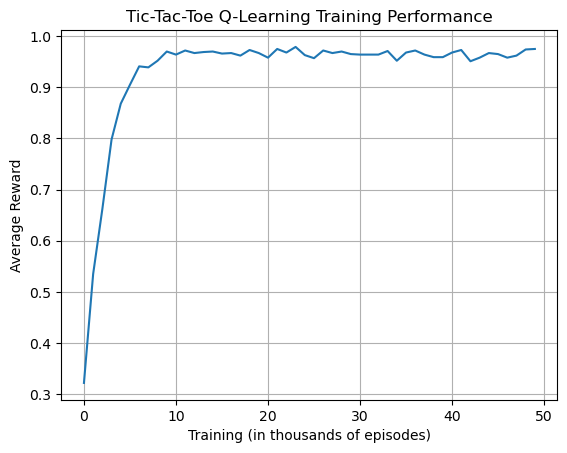


TIC-TAC-TOE GAME
You are O
AI is X
Positions are numbered 0 to 8

Position Guide:
0 | 1 | 2
--+---+--
3 | 4 | 5
--+---+--
6 | 7 | 8

AI played:

  |   |  
--+---+--
  |   |  
--+---+--
X |   |  



Enter your move (0-8):  4



  |   |  
--+---+--
  | O |  
--+---+--
X |   |  


AI played:

  |   |  
--+---+--
  | O |  
--+---+--
X |   | X



Enter your move (0-8):  7



  |   |  
--+---+--
  | O |  
--+---+--
X | O | X


AI played:

  | X |  
--+---+--
  | O |  
--+---+--
X | O | X



...

Invalid position! Try again.


Enter your move (0-8):  0



O | X |  
--+---+--
  | O |  
--+---+--
X | O | X


AI played:

O | X | X
--+---+--
  | O |  
--+---+--
X | O | X



Enter your move (0-8):  5



O | X | X
--+---+--
  | O | O
--+---+--
X | O | X


AI played:

O | X | X
--+---+--
X | O | O
--+---+--
X | O | X

Game Draw!


In [1]:

import numpy as np
import random
import matplotlib.pyplot as plt

# ==========================================
# A. SETTING UP THE ENVIRONMENT
# ==========================================

class TicTacToe:

    def __init__(self):
        self.reset()

    def reset(self):
        self.board = [" "] * 9
        self.done = False
        return tuple(self.board)

    def available_actions(self):
        return [i for i in range(9) if self.board[i] == " "]

    def display(self):
        print()
        for i in range(0, 9, 3):
            print(" | ".join(self.board[i:i+3]))
            if i < 6:
                print("--+---+--")
        print()

    def check_winner(self, player):
        win_positions = [
            (0, 1, 2),
            (3, 4, 5),
            (6, 7, 8),
            (0, 3, 6),
            (1, 4, 7),
            (2, 5, 8),
            (0, 4, 8),
            (2, 4, 6)
        ]

        for a, b, c in win_positions:
            if (self.board[a] == player and
                self.board[b] == player and
                self.board[c] == player):
                return True

        return False

    def step(self, action, player):

        if action not in self.available_actions():
            raise ValueError("Invalid move!")

        self.board[action] = player

        if self.check_winner(player):
            self.done = True
            return tuple(self.board), 1, True

        if len(self.available_actions()) == 0:
            self.done = True
            return tuple(self.board), 0, True

        return tuple(self.board), 0, False


# ==========================================
# B. DEFINING THE RL MODEL (Q-LEARNING)
# ==========================================

class QLearningAgent:

    def __init__(self, alpha=0.1, gamma=0.9,
                 epsilon=1.0, epsilon_decay=0.9995,
                 min_epsilon=0.01):

        self.q_table = {}

        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.min_epsilon = min_epsilon

    def get_q_values(self, state):

        if state not in self.q_table:
            self.q_table[state] = np.zeros(9)

        return self.q_table[state]

    def choose_action(self, state, available_actions,
                      training=True):

        if training and random.random() < self.epsilon:
            return random.choice(available_actions)

        q_values = self.get_q_values(state)

        valid_q_values = [
            (action, q_values[action])
            for action in available_actions
        ]

        max_value = max(value for action, value in valid_q_values)

        best_actions = [
            action for action, value in valid_q_values
            if value == max_value
        ]

        return random.choice(best_actions)

    def learn(self, state, action, reward,
              next_state, done, next_actions):

        current_q = self.get_q_values(state)[action]

        if done:
            target = reward
        else:
            next_q_values = self.get_q_values(next_state)

            target = reward + self.gamma * max(
                next_q_values[a] for a in next_actions
            )

        self.q_table[state][action] += self.alpha * (
            target - current_q
        )

    def decay_epsilon(self):

        self.epsilon = max(
            self.min_epsilon,
            self.epsilon * self.epsilon_decay
        )


# ==========================================
# C. TRAINING THE REINFORCEMENT LEARNING MODEL
# ==========================================

env = TicTacToe()
agent = QLearningAgent()

episodes = 50000

rewards_history = []

for episode in range(episodes):

    state = env.reset()

    done = False
    episode_reward = 0

    while not done:

        # Agent plays as X
        action = agent.choose_action(
            state,
            env.available_actions()
        )

        next_state, reward, done = env.step(action, "X")

        if done:
            if reward == 1:
                agent.learn(
                    state, action, 1,
                    next_state, True, []
                )
                episode_reward = 1
            else:
                agent.learn(
                    state, action, 0,
                    next_state, True, []
                )
                episode_reward = 0

            break

        # Opponent plays randomly as O
        opponent_action = random.choice(
            env.available_actions()
        )

        next_state, opponent_reward, done = env.step(
            opponent_action, "O"
        )

        if done:
            # Agent loses
            agent.learn(
                state, action, -1,
                next_state, True, []
            )
            episode_reward = -1
            break

        # Update Q-table
        agent.learn(
            state,
            action,
            0,
            next_state,
            False,
            env.available_actions()
        )

        state = next_state

    agent.decay_epsilon()

    rewards_history.append(episode_reward)

    if (episode + 1) % 10000 == 0:
        print(
            f"Episode {episode + 1}, "
            f"Epsilon: {agent.epsilon:.4f}"
        )


# ==========================================
# D. DISPLAY TRAINING PERFORMANCE
# ==========================================

window = 1000

average_rewards = [
    np.mean(rewards_history[i:i+window])
    for i in range(0, len(rewards_history), window)
]

plt.plot(average_rewards)
plt.xlabel("Training (in thousands of episodes)")
plt.ylabel("Average Reward")
plt.title("Tic-Tac-Toe Q-Learning Training Performance")
plt.grid()
plt.show()


# ==========================================
# E. TESTING THE TRAINED MODEL
# ==========================================

def play_game():

    env = TicTacToe()

    state = env.reset()

    print("\nTIC-TAC-TOE GAME")
    print("You are O")
    print("AI is X")
    print("Positions are numbered 0 to 8")

    print("\nPosition Guide:")
    print("0 | 1 | 2")
    print("--+---+--")
    print("3 | 4 | 5")
    print("--+---+--")
    print("6 | 7 | 8")

    while True:

        # AI move
        action = agent.choose_action(
            state,
            env.available_actions(),
            training=False
        )

        state, reward, done = env.step(action, "X")

        print("\nAI played:")
        env.display()

        if done:
            if reward == 1:
                print("AI Wins!")
            else:
                print("Game Draw!")
            break

        # Human move
        while True:
            try:
                human_action = int(
                    input("Enter your move (0-8): ")
                )

                if human_action in env.available_actions():
                    break
                else:
                    print("Invalid position! Try again.")

            except ValueError:
                print("Please enter a number from 0 to 8.")

        state, reward, done = env.step(
            human_action, "O"
        )

        env.display()

        if done:
            if reward == 1:
                print("You Win!")
            else:
                print("Game Draw!")
            break


# Start the game
play_game()
